In [2]:
## Running this from the "multiome" conda environment

## Also make sure to manually edit the memory cap for mallet:
## /software/conda/users/od5/multiome/bin/mallet
## MEMORY=1g -> MEMORY=400g

In [3]:
import os

import scanpy as sc
import anndata as ad
import muon as mu
from muon import MuData

from pycisTopic.cistopic_class import CistopicObject
from pycisTopic.lda_models import *
from pycisTopic.clust_vis import *
from pycisTopic.diff_features import *
from pycisTopic.topic_binarization import *
from pycisTopic.topic_qc import *

import snapatac2 as snap

os.environ['R_HOME'] = '/software/conda/users/od5/multiome/lib/R/'

import rpy2
%load_ext rpy2.ipython
import rpy2.robjects as robjects
from rpy2.robjects import r, pandas2ri
pandas2ri.activate()

2026-05-10 20:58:10 - INFO - cffi mode is CFFI_MODE.ANY
2026-05-10 20:58:10 - INFO - R home found: /software/conda/users/od5/multiome/lib/R/
2026-05-10 20:58:11 - INFO - R library path: WARNING: ignoring environment value of R_HOME
/software/lsf-farm22/10.1/linux3.10-glibc2.17-x86_64/lib:/usr/lib/oracle/19.6/client64/lib
2026-05-10 20:58:11 - INFO - LD_LIBRARY_PATH: WARNING: ignoring environment value of R_HOME
/software/lsf-farm22/10.1/linux3.10-glibc2.17-x86_64/lib:/usr/lib/oracle/19.6/client64/lib
2026-05-10 20:58:11 - INFO - Default options to initialize R: rpy2, --quiet, --no-save
by .GlobalEnv when processing object ‘heatmapGS’
by .GlobalEnv when processing object ‘heatmapGS’
by .GlobalEnv when processing object ‘.pbd_env’
2026-05-10 20:58:15 - INFO - R is already initialized. No need to initialize.


In [4]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/'

output_p = (work_dir + 'cistopic/')
os.makedirs(output_p , exist_ok=True)

## make subdirectories:
for d in ['scRNA', 'scATAC', 'figures']:
    os.makedirs((output_p + d + '/'), exist_ok=True)

tmp_dir = '/lustre/scratch125/casm/teams/team215/users/od5/tmp/mallet_dir/immnk/'
os.makedirs(tmp_dir , exist_ok=True)

### 1. Create cistopic object

In [5]:
## Loading object
mdata = mu.read_h5mu(('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/seacells_gex/tf_pilot/batch1/ipsc/seacells_annot_min10cells.h5mu'))

/software/conda/users/od5/multiome/lib/python3.9/site-packages/mudata/_core/mudata.py:578: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  data_mod.loc[:, colname] = col
/software/conda/users/od5/multiome/lib/python3.9/site-packages/mudata/_core/mudata.py:578: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  data_mod.loc[:, colname] = col


In [6]:
mdata

MuData object with n_obs × n_vars = 246 × 118951
  obs:	'perturbation', 'perturbation_purity', 'compactness', 'size'
  obsm:	'X_umap'
  2 modalities
    rna:	246 x 36601
      obs:	'perturbation', 'perturbation_purity', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
      var:	'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
      layers:	'raw'
    atac:	246 x 82350
      obs:	'perturbation', 'perturbation_purity'
      layers:	'raw'

In [7]:
mdata.obs

,rna:perturbation,rna:perturbation_purity,rna:n_genes_by_counts,rna:log1p_n_genes_by_counts,rna:total_counts,rna:log1p_total_counts,rna:pct_counts_in_top_50_genes,rna:pct_counts_in_top_100_genes,rna:pct_counts_in_top_200_genes,rna:pct_counts_in_top_500_genes,atac:perturbation,atac:perturbation_purity,perturbation,perturbation_purity,compactness,size
TCF7-SEACell-30,TCF7,1.0,12704,9.449751,54069.817400,10.898050,3.463336,6.062271,10.492979,20.560861,TCF7,1.0,TCF7,1.0,2.601516e-01,13
CEBPD-SEACell-11,CEBPD,1.0,13601,9.517972,59806.739891,10.998890,3.259936,5.525603,9.458056,18.989564,CEBPD,1.0,CEBPD,1.0,5.668808e+00,14
TCF7-SEACell-12,TCF7,1.0,15631,9.657075,93773.432237,11.448648,3.128531,5.382958,9.354212,18.901952,TCF7,1.0,TCF7,1.0,6.001987e-01,21
RUNX2-SEACell-1,RUNX2,1.0,18337,9.816731,335998.655379,12.724865,3.183960,5.472090,9.411482,18.885966,RUNX2,1.0,RUNX2,1.0,4.216010e-01,79
CEBPD-SEACell-19,CEBPD,1.0,12055,9.397318,48429.942496,10.787894,3.654876,6.424327,10.999068,21.125926,CEBPD,1.0,CEBPD,1.0,1.151300e+00,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCF7-SEACell-19,TCF7,1.0,12735,9.452188,62565.059516,11.043978,3.660234,6.155084,10.303045,20.216276,TCF7,1.0,TCF7,1.0,4.435700e+00,16
Control-SEACell-8,Control,1.0,14504,9.582249,78327.551421,11.268667,3.219917,5.570595,9.622766,19.393369,Control,1.0,Control,1.0,2.543382e-02,18
Control-SEACell-23,Control,1.0,15285,9.634693,107930.223947,11.589249,3.214406,5.535090,9.555638,19.375521,Control,1.0,Control,1.0,4.246273e-01,25
CEBPD-SEACell-17,CEBPD,1.0,13374,9.501143,59876.368083,11.000054,3.327706,5.745120,9.902686,19.780738,CEBPD,1.0,CEBPD,1.0,5.270098e-02,14


In [8]:
## First, we need to subset to peaks that are actually accessible in our subset of cells
atac_fractions = pd.read_csv('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/archr_peaks_f_access_by_cellType.csv', index_col=0)
print(atac_fractions.shape)
## Subset for cell types of interest
atac_fractions = atac_fractions.loc[:,atac_fractions.columns[atac_fractions.columns.isin(mdata.obs['perturbation'].unique())]]
print(atac_fractions.shape)

## Accessibility cutoff - 5% (instead of 2.5% to be able to run scenicplus) of cells in at least one cell type
robust_peaks = atac_fractions.index[atac_fractions.max(axis=1) > 0.05]
print(len(robust_peaks))

(82350, 10)
(82350, 9)
36627


In [9]:
## Subset mdata object
atac = mdata['atac'][:,mdata['atac'].var_names.isin(robust_peaks)].copy()
atac

AnnData object with n_obs × n_vars = 246 × 36627
    obs: 'perturbation', 'perturbation_purity'
    layers: 'raw'

In [10]:
## Initialise cistopic object
cistopic_obj = CistopicObject(
    fragment_matrix=atac.layers['raw'].T,
    binary_matrix=(atac.layers['raw'].T > 0).astype(np.bool_),
    cell_names=mdata.obs_names,
    region_names=atac.var_names,
    cell_data=mdata.obs,
    region_data=atac.var,
    path_to_fragments="",
    project = "cistopic_atac"
    )

In [11]:
## Convert any categorical variables to str (to avoid some downstream errors with visualisation functions)
for x in ['perturbation']:
    cistopic_obj.cell_data[x] = cistopic_obj.cell_data[x].astype(str)

In [12]:
pickle.dump(cistopic_obj,
            open(os.path.join(output_p, 'scATAC/cistopic_obj.pkl'), 'wb'))

### 2. Run cistopic for a range of topic numbers

In [13]:
## Job submission fails from within the shell.
## Simply copy paste the following commands in a shell script
n_topics=[5,10,20,30,40,50,60,70,80,90,100]
path_to_mallet_binary='/software/conda/users/od5/multiome/bin/mallet'
os.makedirs((output_p + '/scATAC/models'), exist_ok=True)
mallet_mem = '100G'

print('cd ' + os.getcwd())
print('conda activate multiome')
for topic in n_topics:
    print('/nfs/casm/team215mg/users/od5/scripts/jsub lsf -n cistopic_' + str(topic) + \
          ' -q normal -m 100g -c 16 "python /nfs/casm/team215mg/users/od5/scripts/pycistopic_wrapper.py -i ' + \
          output_p + 'scATAC/cistopic_obj.pkl -n ' + \
          str(topic) + ' -c 16 -m 100G -o ' + output_p + 'scATAC/models" | bsub -G team215-grp')

cd /nfs/casm/team215mg/users/od5/projects/celltherapy/ipsc/multiome/tf_pilot/005_GRNs/001_ipsc
conda activate multiome
/nfs/casm/team215mg/users/od5/scripts/jsub lsf -n cistopic_5 -q normal -m 100g -c 16 "python /nfs/casm/team215mg/users/od5/scripts/pycistopic_wrapper.py -i /lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/cistopic/scATAC/cistopic_obj.pkl -n 5 -c 16 -m 100G -o /lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/cistopic/scATAC/models" | bsub -G team215-grp
/nfs/casm/team215mg/users/od5/scripts/jsub lsf -n cistopic_10 -q normal -m 100g -c 16 "python /nfs/casm/team215mg/users/od5/scripts/pycistopic_wrapper.py -i /lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/cistopic/scATAC/cistopic_obj.pkl -n 10 -c 16 -m 100G -o /lustre/scratch125/casm/teams/team215/users/od5/projects/cellthera

### 3. Evaluate topic modelling result

In [14]:
with open(os.path.join(output_p, 'scATAC/cistopic_obj.pkl'), 'rb') as f:
    cistopic_obj = pickle.load(f)

In [15]:
# Load models
models=[]

for f in os.listdir(output_p + 'scATAC/models/') :
    if "Topic" in f:
        infile = open((output_p + 'scATAC/models/' + f), 'rb')
        mod=pickle.load(infile)
        infile.close()
        models.append(mod)

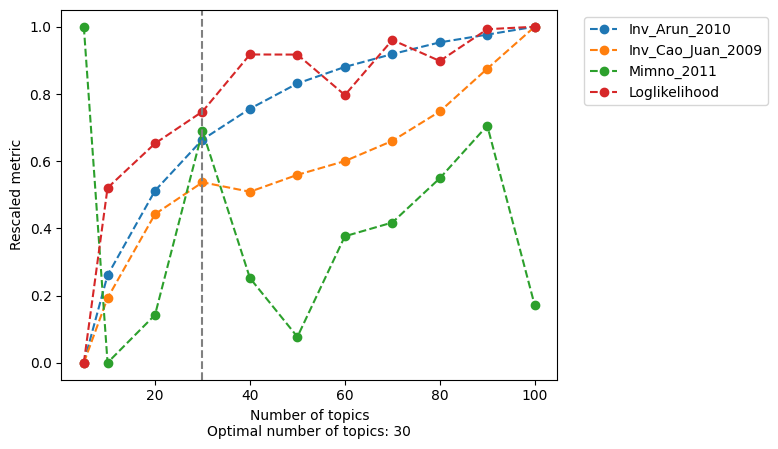

In [32]:
## Determined based on the different metrics
topic_number = 30

model=evaluate_models(models,
                  select_model=topic_number, 
                  return_model=True, 
                  metrics=['Arun_2010','Cao_Juan_2009', 'Minmo_2011', 'loglikelihood'],
                  plot_metrics=False,
                      save= (output_p + 'figures/topic_metrics.png'))

In [33]:
## Adding selected model to cistopic
cistopic_obj.add_LDA_model(model)

In [34]:
run_umap(cistopic_obj, target  = 'cell', scale=True)

2026-05-11 08:54:54 - INFO - Running UMAP
/software/conda/users/od5/multiome/lib/python3.9/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


In [35]:
## And save
pickle.dump(cistopic_obj, open(os.path.join(output_p, 'scATAC/cistopic_obj.pkl'), 'wb'))

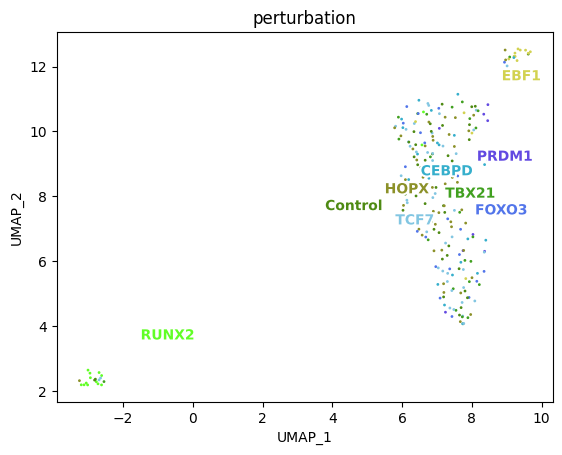

In [36]:
## Visualising results
plot_metadata(cistopic_obj, 
              reduction_name = 'UMAP',
              variables = ['perturbation'], dot_size=1)

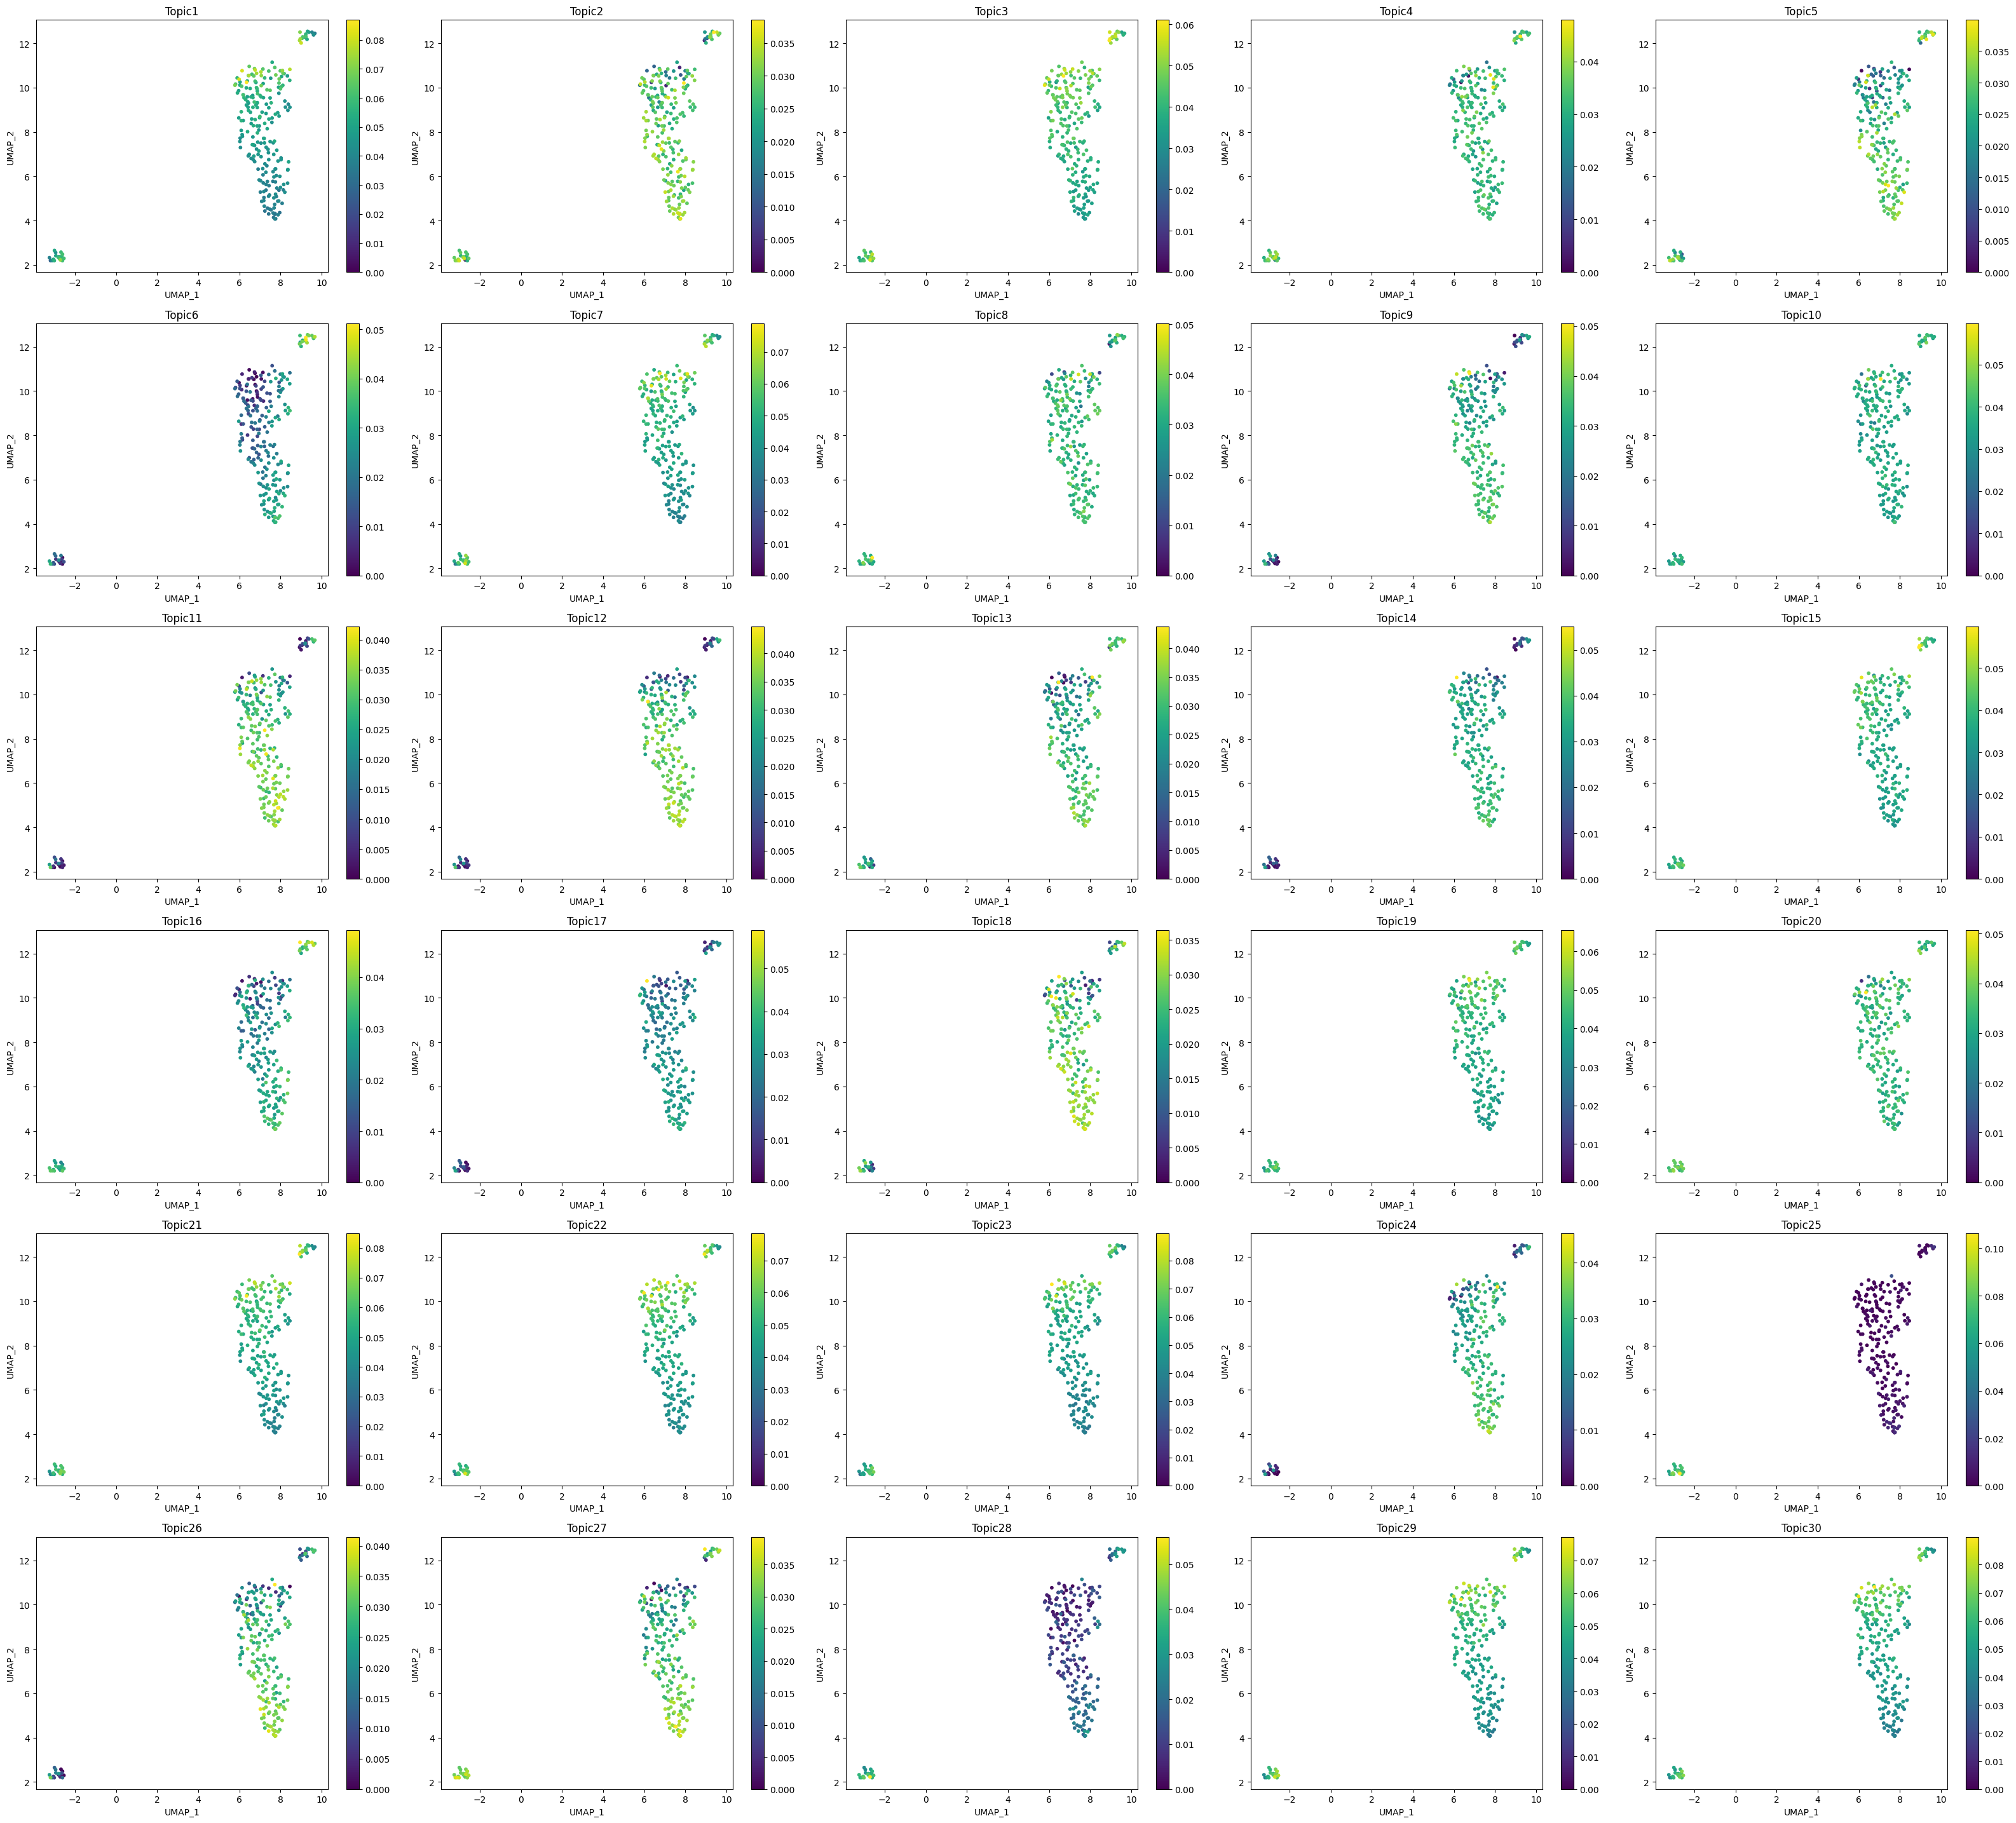

In [37]:
## Plot topic contributions
plot_topic(cistopic_obj,
            reduction_name = 'UMAP',
            target = 'cell',
            num_columns=5,
            save= (output_p + 'figures/topic_contr.png'))

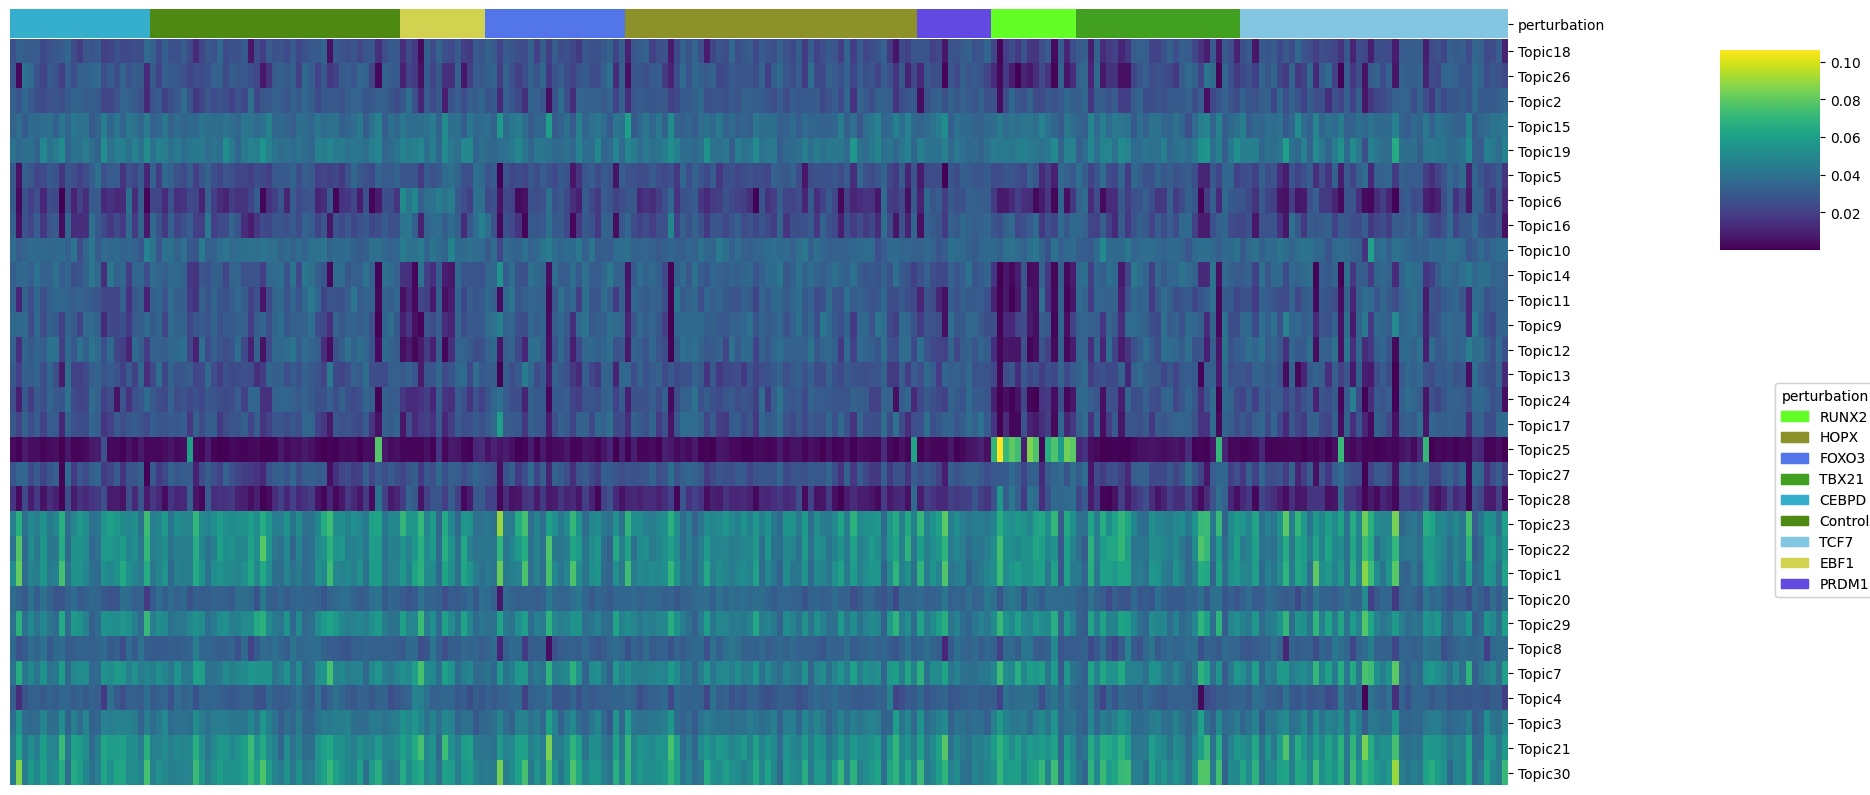

In [38]:
cell_topic_heatmap(cistopic_obj,
                     variables = ['perturbation'], 
                   remove_nan=False,
                     scale = False,
                     legend_loc_x = 1.05,
                     legend_loc_y = -1.2,
                     legend_dist_y = -1,
                     figsize=(20,10),
                     save = (output_p + 'figures/topics_heatmap_topic_contr.png'))

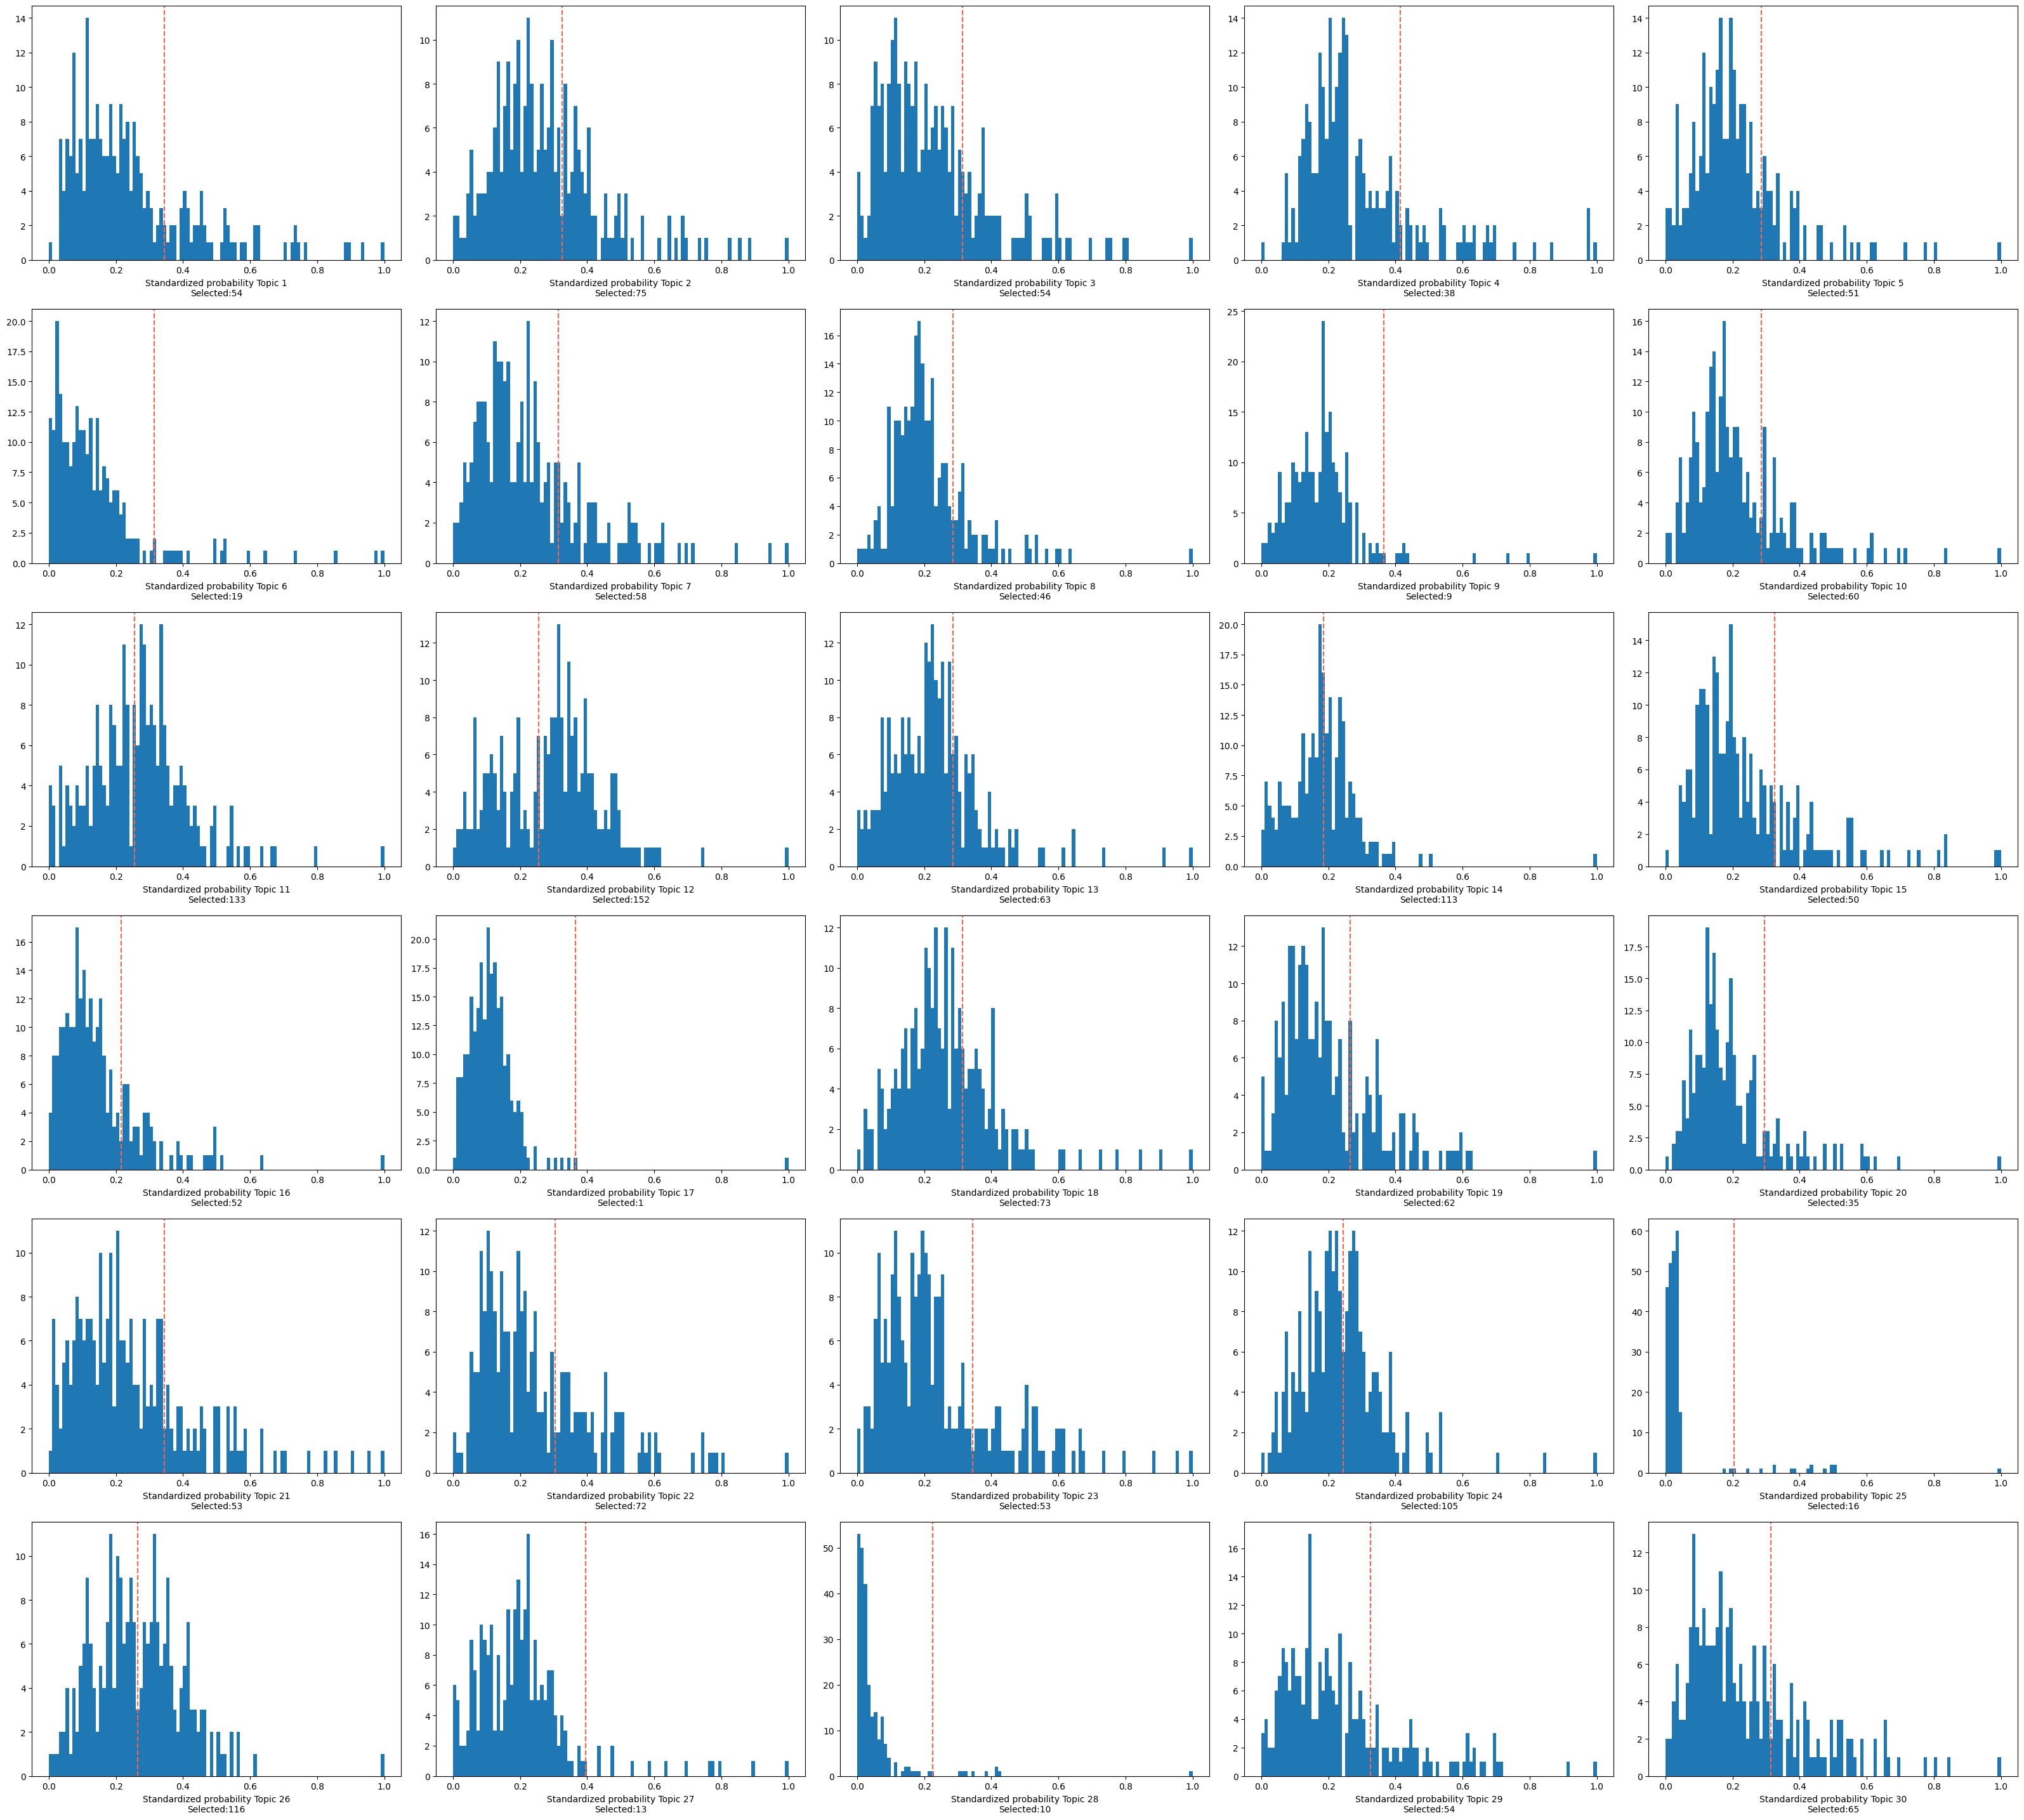

In [39]:
binarized_cell_topic = binarize_topics(cistopic_obj, target='cell', method='otsu', plot=True, num_columns=5, nbins=100)

In [40]:
region_bin_topics_top3k = binarize_topics(cistopic_obj, method='ntop', ntop = 3000)
region_bin_topics_otsu = binarize_topics(cistopic_obj, method='otsu')

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [41]:
## Export:
pickle.dump(region_bin_topics_top3k,
            open(os.path.join(output_p, 'scATAC/region_bin_topics_top3K.pkl'), 'wb'))
pickle.dump(region_bin_topics_otsu,
            open(os.path.join(output_p, 'scATAC/region_bin_topics_otsu.pkl'), 'wb'))

In [42]:
## Topic QC
topic_qc_metrics = compute_topic_metrics(cistopic_obj)

In [43]:
topic_qc_metrics

,Log10_Assignments,Assignments,Cells_in_binarized_topic,Regions_in_binarized_topic,Coherence,Marginal_topic_dist,Gini_index
Topic1,5.478416,300896.0,54,2724,-0.043726,0.048402,0.118826
Topic2,5.244893,175749.0,75,2904,-0.293616,0.028302,0.112726
Topic3,5.406424,254932.0,54,2702,-0.096372,0.041020,0.087285
Topic4,5.293405,196519.0,38,2867,-0.215403,0.031638,0.086315
Topic5,5.219207,165656.0,51,2845,-0.381256,0.026681,0.147314
Topic6,5.132067,135540.0,19,2867,-0.532920,0.021843,0.278421
Topic7,5.466104,292485.0,58,2670,-0.067287,0.047052,0.108165
Topic8,5.310475,204397.0,46,3092,-0.259431,0.032904,0.083129
Topic9,5.265459,184272.0,9,3092,-0.349063,0.029672,0.170943
Topic10,5.342896,220240.0,60,2880,-0.167894,0.035448,0.064909


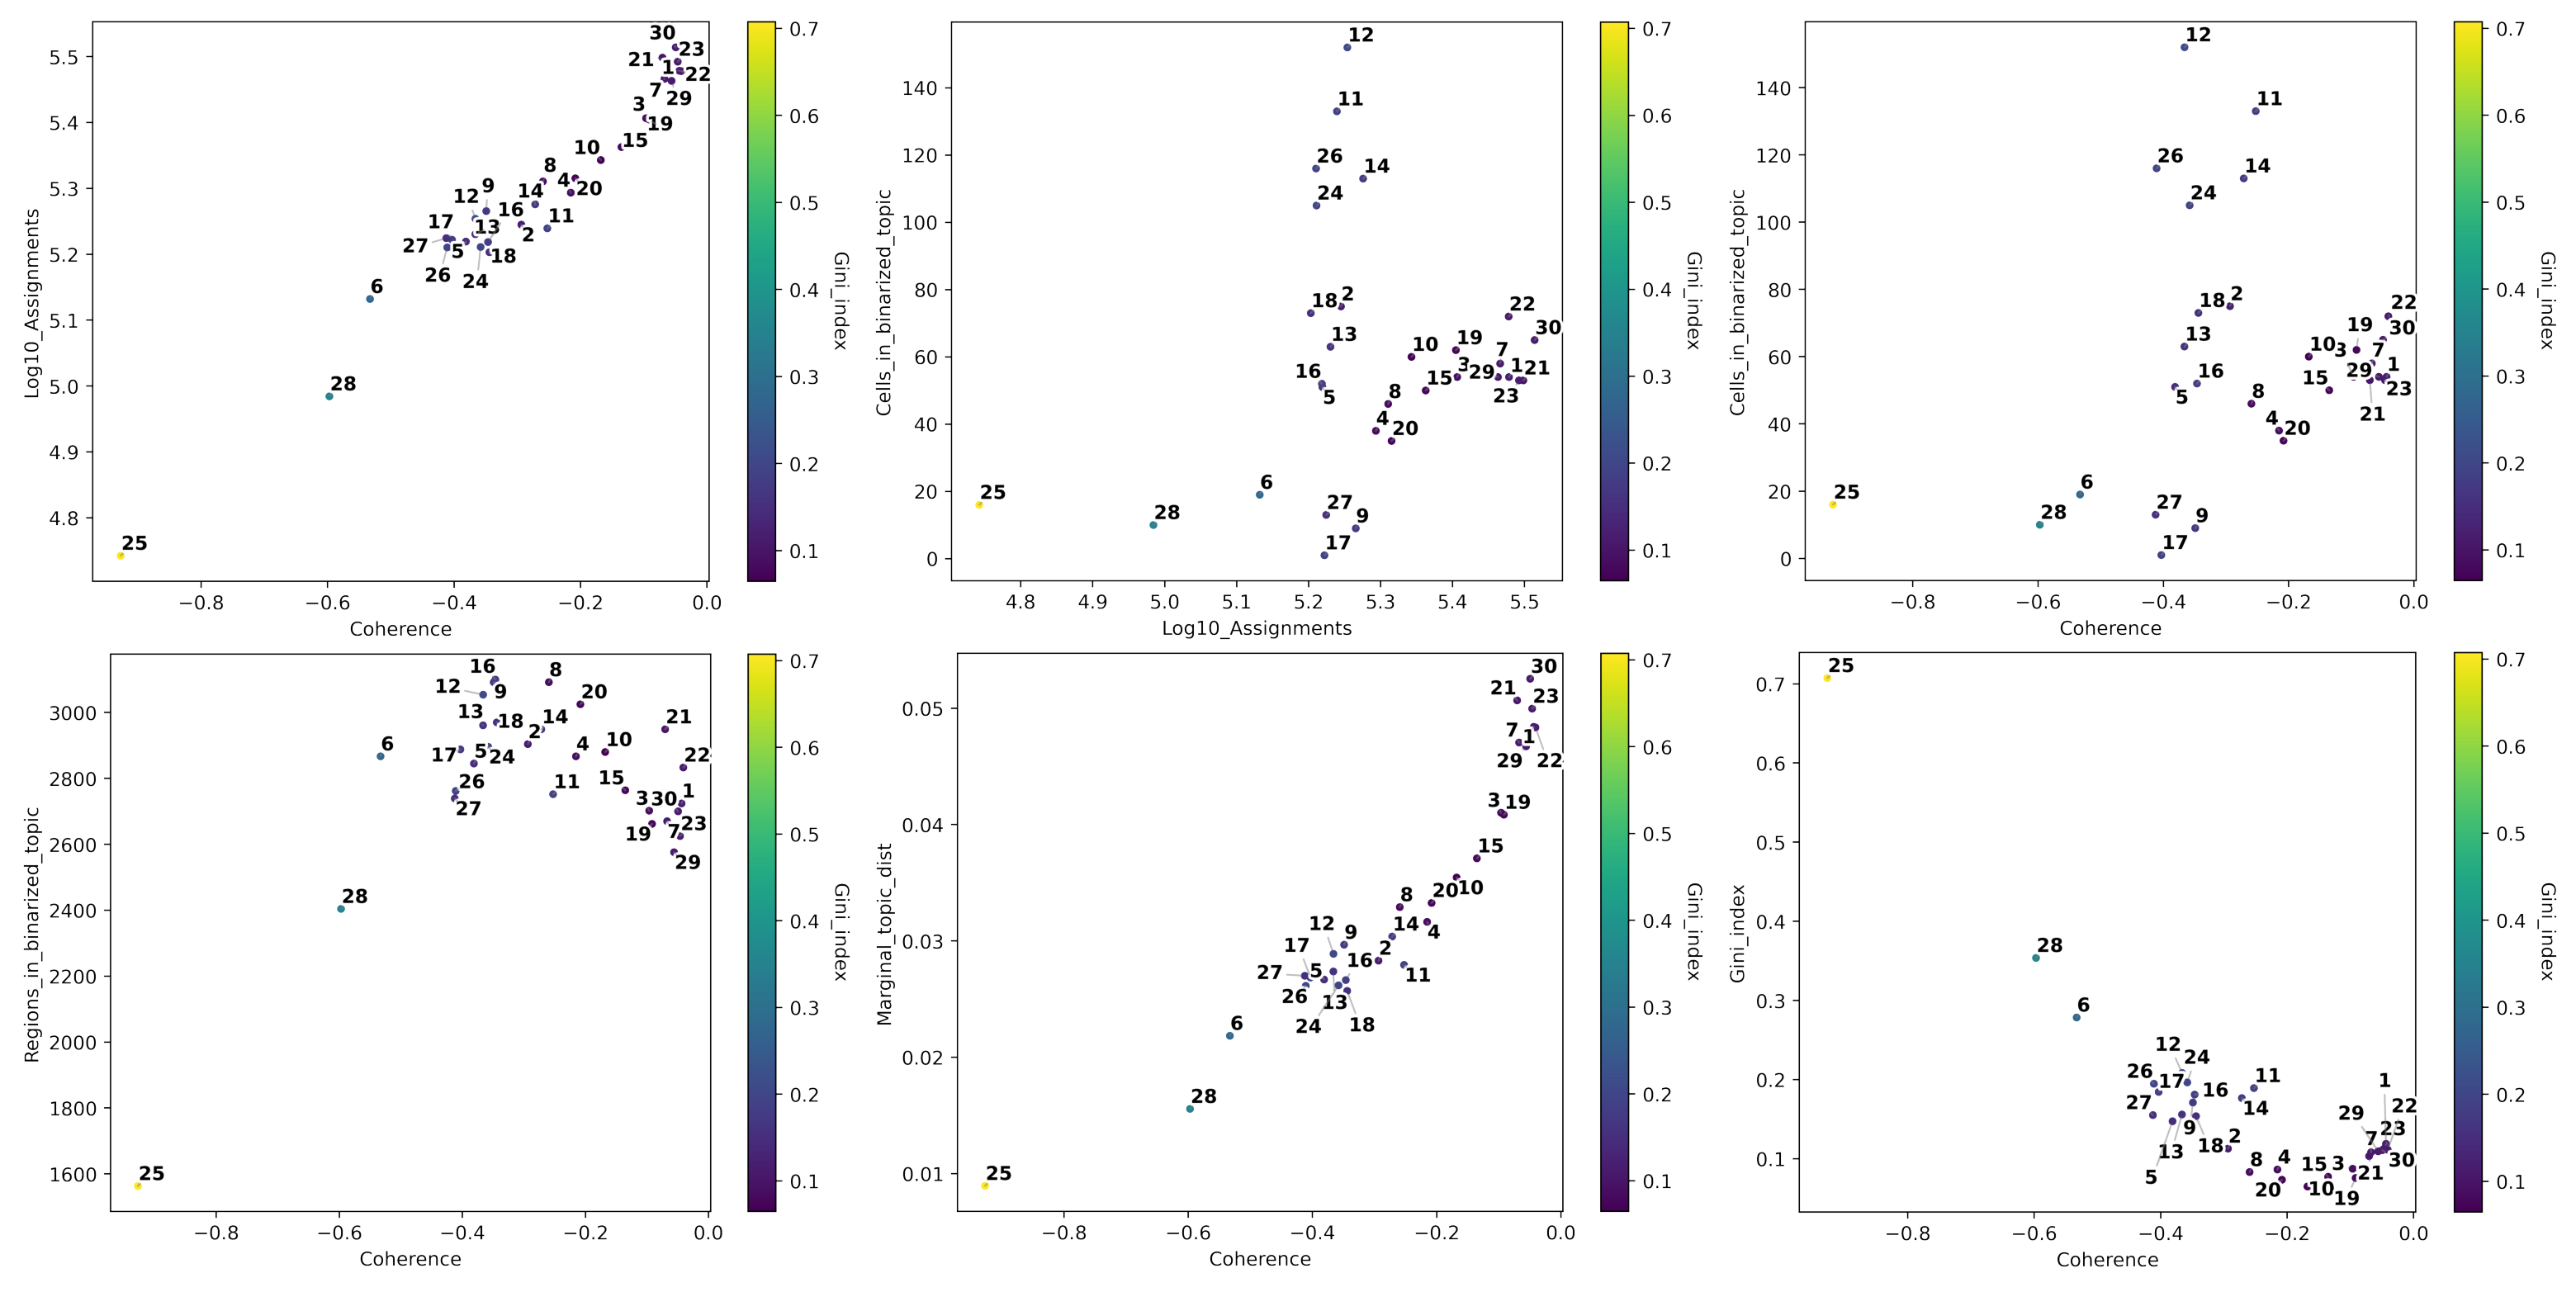

In [44]:
fig_dict={}
fig_dict['CoherenceVSAssignments']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Log10_Assignments', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['AssignmentsVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Log10_Assignments', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSRegions_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Regions_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSMarginal_dist']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Marginal_topic_dist', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSGini_index']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Gini_index', var_color='Gini_index', plot=False, return_fig=True)
# Plot topic stats in one figure
fig=plt.figure(figsize=(40, 43))
i = 1
for fig_ in fig_dict.keys():
    plt.subplot(2, 3, i)
    img = fig2img(fig_dict[fig_]) #To convert figures to png to plot together, see .utils.py. This converts the figure to png.
    plt.imshow(img)
    plt.axis('off')
    i += 1
plt.subplots_adjust(wspace=0, hspace=-0.70)

In [45]:
## Explaining topics based on different covariates.
## Here we start with cell type and sample ID, but we can eventually include aspects such as organ and stimulation status
variables = ['perturbation']
topic_mat = cistopic_obj.selected_model.cell_topic.transpose()
cell_anno = cistopic_obj.cell_data

In [46]:
%%R -i topic_mat -i cell_anno -i variables
## Shifting to R as this is easier to do here:
library(tidyverse)

nTopics <- ncol(topic_mat)

topic_mat$cell <- row.names(topic_mat)
cell_anno$cell <- row.names(cell_anno)

## Put together
cell_anno <- left_join(cell_anno, topic_mat)

## Create designs based on provided variables
designs <- c(paste0('~', paste(variables, collapse = '+')),
  sapply(variables, function(v) {
    paste0('~', paste(variables[variables!=v], collapse = '+'))
    })
  )
names(designs) <- c('full', variables)
designs

## For each topic, predict cell loadings based on the different covariates
topic_stats <- Reduce(bind_rows, lapply(1:nTopics, function(i) {

  ## Fit a model based on each design (full vs each variable omitted one-by-one)
  models <- lapply(designs, function(d) {
    m <- lm(paste0('Topic', i, d), data = cell_anno)
  })
  names(models) <- names(designs)

  ## Assess the impact of omitting each variable (i.e., its contribution to topic loadings) using anova
  df <- Reduce(left_join, lapply(variables, function(v){
    r <- anova(models[['full']], models[[v]])
    df <- data.frame(
      Topic = paste0('Topic', i),
      F = r$F[2],
      P = r$`Pr(>F)`[2]
    )
    colnames(df)[2:3] <- paste0(colnames(df)[2:3], '_', v)
    return(df)
  }))
  return(df)
}))

Joining with `by = join_by(cell)`
Error in str2lang(x) : <text>:2:0: unexpected end of input
1: Topic1~
   ^


RInterpreterError: Failed to parse and evaluate line "## Shifting to R as this is easier to do here:\nlibrary(tidyverse)\n\nnTopics <- ncol(topic_mat)\n\ntopic_mat$cell <- row.names(topic_mat)\ncell_anno$cell <- row.names(cell_anno)\n\n## Put together\ncell_anno <- left_join(cell_anno, topic_mat)\n\n## Create designs based on provided variables\ndesigns <- c(paste0('~', paste(variables, collapse = '+')),\n  sapply(variables, function(v) {\n    paste0('~', paste(variables[variables!=v], collapse = '+'))\n    })\n  )\nnames(designs) <- c('full', variables)\ndesigns\n\n## For each topic, predict cell loadings based on the different covariates\ntopic_stats <- Reduce(bind_rows, lapply(1:nTopics, function(i) {\n\n  ## Fit a model based on each design (full vs each variable omitted one-by-one)\n  models <- lapply(designs, function(d) {\n    m <- lm(paste0('Topic', i, d), data = cell_anno)\n  })\n  names(models) <- names(designs)\n\n  ## Assess the impact of omitting each variable (i.e., its c

In [ ]:
%%R
ggplot(topic_stats, aes(x=F_sample_ID, y=F_anno_v1_nuc_gex)) +
  geom_point() +
  geom_text(data = filter(topic_stats, F_sample_ID > 300 | F_anno_v1_nuc_gex > 300), aes(label=Topic)) +
  theme_bw()

In [ ]:
%%R
head(topic_stats)

In [ ]:
cistopic_obj.selected_model.cell_topic.to_csv((output_p + 'scATAC/cell_x_topic_mat_topics.csv'))
cistopic_obj.cell_data.to_csv((output_p + 'scATAC/cell_data_df.csv'))